# Final Test evaluation

E5 evaluates the seven predeclared configurations and applies the already-frozen CatBoost calibrator and B-selected threshold. No training, calibration fitting, threshold search or model selection is performed here. CatBoost remains the selected model regardless of the Test ranking. Test outcomes have previously appeared in EDA/Stage 3, so this is not a completely untouched research cohort.

This notebook blocks a second completed evaluation for the same final configuration. Inspect saved results instead of rerunning Test to make new choices.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Verify the frozen E3/E4 decision

Validate config lineage, artifact hashes and environment before making any Test predictions.

In [2]:
def sha256_file(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

from scipy.special import logit
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    confusion_matrix, precision_score, recall_score, f1_score, precision_recall_curve,
)
FINAL_CONFIG_PATH = ROOT / "outputs/tables/machine_learning/ml_calibration/20261111_154951_108593/final_config.json"
final_config = json.loads(FINAL_CONFIG_PATH.read_text(encoding="utf-8"))
final_config_hash = sha256_file(FINAL_CONFIG_PATH)
assert final_config["status"] == "frozen_ready_for_test"
assert final_config["model"] == "CatBoost" and final_config["configuration"] == "unweighted_baseline"
selection_path = ROOT / final_config["selection_config"]
assert sha256_file(selection_path) == final_config["selection_sha256"]
selection = json.loads(selection_path.read_text(encoding="utf-8"))
for name, digest in final_config["input_hashes"].items():
    assert sha256_file(ROOT / name) == digest, name
assert sha256_file(ROOT / final_config["frozen_pipeline"]) == final_config["pipeline_sha256"]
assert sha256_file(ROOT / final_config["calibrator"]) == final_config["calibrator_sha256"]
for name, version in final_config["package_versions"].items():
    if name != "python":
        assert importlib.metadata.version(name) == version, name
for record in (ROOT / "outputs/tables/machine_learning/ml_test").glob("*/evaluation_manifest.json"):
    existing = json.loads(record.read_text(encoding="utf-8"))
    if existing.get("status") == "completed" and existing.get("final_config_sha256") == final_config_hash:
        raise RuntimeError(f"Final Test evaluation already completed: {record}. Inspect its saved results; do not retune on Test.")
threshold = float(final_config["threshold"])
assert final_config["threshold_probability_type"] == "calibrated"
print("Selected classifier: CatBoost unweighted baseline")
print("Frozen calibrated threshold:", threshold)


Selected classifier: CatBoost unweighted baseline
Frozen calibrated threshold: 0.054178902872422004


## Freeze the seven-model registry and Test evaluation plan

Resolve all pipelines from the already-frozen comparison, not from the latest run or Test scores. Save the registry before loading Test.

In [3]:
comparison_path = ROOT / selection["comparison_source"]
assert sha256_file(comparison_path) == selection["comparison_sha256"]
source_map = json.loads((comparison_path.parent / "comparison_source.json").read_text(encoding="utf-8"))
registry = []
for group, names in [
    ("ml_logistic_random_forest", ["LogisticRegression", "RandomForest"]),
    ("ml_lightgbm_xgboost", ["LightGBM", "XGBoost"]),
    ("ml_catboost_dummy", ["CatBoost", "DummyClassifier"]),
    ("ml_catboost_weighted", ["CatBoostWeighted"]),
]:
    source = comparison_path.parent if group == "ml_catboost_weighted" else ROOT / source_map[group]
    recorded_hashes = {k.replace("\\", "/"): v for k, v in json.loads((source / "input_hashes.json").read_text(encoding="utf-8")).items()}
    assert recorded_hashes == selection["input_hashes"] or recorded_hashes == selection["input_lf_hashes"], source
    versions = json.loads((source / "package_versions.json").read_text(encoding="utf-8"))
    for package, version in versions.items():
        if package != "python":
            assert importlib.metadata.version(package) == version, (source, package)
    for name in names:
        path = ROOT / "outputs/models" / group / source.name / f"{name}.joblib"
        if name == "CatBoost":
            assert sha256_file(path) == final_config["pipeline_sha256"]
            path = ROOT / final_config["frozen_pipeline"]
        assert path.is_file(), path
        registry.append(dict(
            model=name, selected_on_validation_a=(name == "CatBoost"),
            pipeline=path.relative_to(ROOT).as_posix(),
            pipeline_sha256=sha256_file(path),
            source_run=source.relative_to(ROOT).as_posix(),
        ))
assert len(registry) == 7 and len({r["model"] for r in registry}) == 7
run = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
tables = ROOT / "outputs/tables/machine_learning/ml_test" / run
figures = ROOT / "outputs/figures/ml_test" / run
for path in [tables, figures]:
    path.mkdir(parents=True, exist_ok=False)
pd.DataFrame(registry).to_csv(tables / "model_registry.csv", index=False)
plan = dict(
    final_config=FINAL_CONFIG_PATH.relative_to(ROOT).as_posix(), final_config_sha256=final_config_hash,
    selection_config=final_config["selection_config"], model_registry=registry,
    selected_model="CatBoost", threshold=threshold,
    calibrator=final_config["calibrator"], calibrator_sha256=final_config["calibrator_sha256"],
    test_expected_orders=9445, test_expected_late=504,
    input_hashes=final_config["input_hashes"],
    classifier_refitted=False, calibrator_refitted=False, threshold_reselected=False,
    selection_changed_after_test=False,
    limitation="Test outcomes previously appeared in EDA/Stage 3. No choices may be changed based on these Test results.",
)
(tables / "evaluation_plan.json").write_text(json.dumps(plan, indent=2), encoding="utf-8")
display(pd.DataFrame(registry)[["model", "selected_on_validation_a", "source_run"]])


,model,selected_on_validation_a,source_run
0,LogisticRegression,False,outputs/tables/ml_logistic_random_forest/20261...
1,RandomForest,False,outputs/tables/ml_logistic_random_forest/20261...
2,LightGBM,False,outputs/tables/ml_lightgbm_xgboost/20261111_14...
3,XGBoost,False,outputs/tables/ml_lightgbm_xgboost/20261111_14...
4,CatBoost,True,outputs/tables/ml_catboost_dummy/20261111_1528...
5,DummyClassifier,False,outputs/tables/ml_catboost_dummy/20261111_1528...
6,CatBoostWeighted,False,outputs/tables/ml_catboost_weighted/20261111_1...


## Load only the Test cohort

Use the shared manifest and all eligible Test orders, including missing predictor values handled by each saved pipeline.

In [4]:
features = final_config["features"]
needed_columns = ["order_id", "is_late", *features]
data = pd.read_csv(ROOT / "data/processed/research_data_weather_price_holiday_assume_utc.csv", usecols=needed_columns)
manifest = pd.read_csv(ROOT / "data/ml_preparation/split_manifest.csv")
assert data.order_id.is_unique and manifest.order_id.is_unique
orders = manifest.loc[manifest.split.eq("test"), ["order_id", "split"]]
test = orders.merge(data, on="order_id", how="left", validate="one_to_one", indicator=True)
del data
assert test["_merge"].eq("both").all() and len(test) == 9445
assert test.is_late.isin([0, 1]).all() and test.is_late.eq(1).sum() == 504
features = final_config["features"]
cat = final_config["categorical_features"]
num = [name for name in features if name not in cat]
assert features == pd.read_csv(ROOT / "docs/predictor_list.csv").feature.tolist()
for name in cat:
    test[name] = test[name].map(lambda value: str(value) if pd.notna(value) else np.nan)
for name in num:
    test[name] = pd.to_numeric(test[name], errors="raise").replace([np.inf, -np.inf], np.nan)
y_test = test.is_late.astype(int).to_numpy()
sample_summary = dict(split="test", n=len(test), late=int(y_test.sum()), prevalence=float(y_test.mean()))
pd.DataFrame([sample_summary]).to_csv(tables / "sample_summary.csv", index=False)
display(pd.DataFrame([sample_summary]))


,split,n,late,prevalence
0,test,9445,504,0.053362


## Score seven fixed pipelines

Only predict_proba is called. The Test ranking is descriptive and cannot change the selected classifier.

In [5]:
def probability_metrics(name, probabilities, probability_type):
    return dict(
        model=name, split="test", probability_type=probability_type,
        n=len(y_test), late=int(y_test.sum()), prevalence=float(y_test.mean()),
        selected_on_validation_a=(name == "CatBoost"),
        mean_probability=float(probabilities.mean()),
        AP=average_precision_score(y_test, probabilities),
        ROC_AUC=roc_auc_score(y_test, probabilities),
        Brier=brier_score_loss(y_test, probabilities),
        LogLoss=log_loss(y_test, probabilities, labels=[0, 1]),
    )
raw_rows = []
prediction_parts = []
raw_probabilities = {}
for record in registry:
    pipeline = joblib.load(ROOT / record["pipeline"])
    probabilities = pipeline.predict_proba(test[features])[:, 1]
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    raw_probabilities[record["model"]] = probabilities
    raw_rows.append(probability_metrics(record["model"], probabilities, "raw"))
    prediction_parts.append(pd.DataFrame(dict(
        order_id=test.order_id.to_numpy(), split="test", model=record["model"], y_true=y_test,
        raw_probability=probabilities, calibrated_probability=np.nan, prediction=np.nan, threshold=np.nan,
    )))
    del pipeline
    import gc
    gc.collect()
raw_comparison = pd.DataFrame(raw_rows).sort_values("AP", ascending=False)
raw_comparison.to_csv(tables / "seven_model_test_comparison.csv", index=False)
np.testing.assert_allclose(raw_probabilities["DummyClassifier"], 3720 / 57449)
display(raw_comparison)


C:\Users\LENOVO\OneDrive\Desktop\PTTK\.venv-boosting\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,split,probability_type,n,late,prevalence,selected_on_validation_a,mean_probability,AP,ROC_AUC,Brier,LogLoss
1,RandomForest,test,raw,9445,504,0.053362,False,0.075299,0.097815,0.703794,0.049924,0.200420
2,LightGBM,test,raw,9445,504,0.053362,False,0.051118,0.089018,0.677041,0.050339,0.201280
3,XGBoost,test,raw,9445,504,0.053362,False,0.060042,0.087707,0.682035,0.050587,0.200834
4,CatBoost,test,raw,9445,504,0.053362,True,0.052313,0.082843,0.674094,0.050143,0.200854
0,LogisticRegression,test,raw,9445,504,0.053362,False,0.063942,0.081244,0.629901,0.051185,0.206977
6,CatBoostWeighted,test,raw,9445,504,0.053362,False,0.387777,0.073914,0.624723,0.176899,0.535125
5,DummyClassifier,test,raw,9445,504,0.053362,False,0.064753,0.053362,0.500000,0.050644,0.209432


## Apply the frozen sigmoid calibrator and B-selected threshold

Use the exact E4 transform and threshold. Do not fit or choose between raw/calibrated scores after viewing Test.

In [6]:
calibrator = joblib.load(ROOT / final_config["calibrator"])
assert calibrator.get_params() == final_config["calibrator_parameters"]
np.testing.assert_allclose(calibrator.coef_[0, 0], final_config["slope"], rtol=0, atol=0)
np.testing.assert_allclose(calibrator.intercept_[0], final_config["intercept"], rtol=0, atol=0)
raw_selected = raw_probabilities["CatBoost"]
epsilon = float(final_config["clipping_epsilon"])
log_odds = logit(np.clip(raw_selected, epsilon, 1 - epsilon)).reshape(-1, 1)
calibrated_probability = calibrator.predict_proba(log_odds)[:, 1]
assert np.isfinite(calibrated_probability).all()
prediction = (calibrated_probability >= threshold).astype(int)
selected_comparison = pd.DataFrame([
    probability_metrics("CatBoost", raw_selected, "raw"),
    probability_metrics("CatBoost", calibrated_probability, "calibrated"),
])
selected_comparison.to_csv(tables / "selected_calibration_comparison.csv", index=False)
tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
threshold_metrics = dict(
    model="CatBoost", split="test", probability_type="calibrated", threshold=threshold,
    n=len(y_test), late=int(y_test.sum()),
    Precision=precision_score(y_test, prediction, zero_division=0),
    Recall=recall_score(y_test, prediction), F1=f1_score(y_test, prediction),
    alert_rate=float(prediction.mean()), alerts=int(prediction.sum()),
    TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp),
    validation_b_target_recall=final_config["min_recall"],
    test_recall_target_met=bool(recall_score(y_test, prediction) >= final_config["min_recall"]),
)
# Target attainment is reported, never used as a pass/fail condition or to change the threshold.
pd.DataFrame([threshold_metrics]).to_csv(tables / "selected_threshold_metrics.csv", index=False)
all_predictions = pd.concat(prediction_parts, ignore_index=True)
selected_mask = all_predictions.model.eq("CatBoost")
all_predictions.loc[selected_mask, "calibrated_probability"] = calibrated_probability
all_predictions.loc[selected_mask, "prediction"] = prediction
all_predictions.loc[selected_mask, "threshold"] = threshold
all_predictions.to_csv(tables / "test_predictions.csv", index=False)
all_predictions.loc[selected_mask].to_csv(tables / "selected_test_predictions.csv", index=False)
display(selected_comparison)
display(pd.DataFrame([threshold_metrics]))


,model,split,probability_type,n,late,prevalence,selected_on_validation_a,mean_probability,AP,ROC_AUC,Brier,LogLoss
0,CatBoost,test,raw,9445,504,0.053362,True,0.052313,0.082843,0.674094,0.050143,0.200854
1,CatBoost,test,calibrated,9445,504,0.053362,True,0.118092,0.082843,0.674094,0.057522,0.227891


,model,split,probability_type,threshold,n,late,Precision,Recall,F1,alert_rate,alerts,TN,FP,FN,TP,validation_b_target_recall,test_recall_target_met
0,CatBoost,test,calibrated,0.054179,9445,504,0.064215,0.94246,0.120238,0.783166,7397,2019,6922,29,475,0.7,True


## Plot descriptive Test results

Calibration bins use the E4 rule: 10 fixed equal-width bins, with counts and empty bins retained. No Test threshold search is performed.

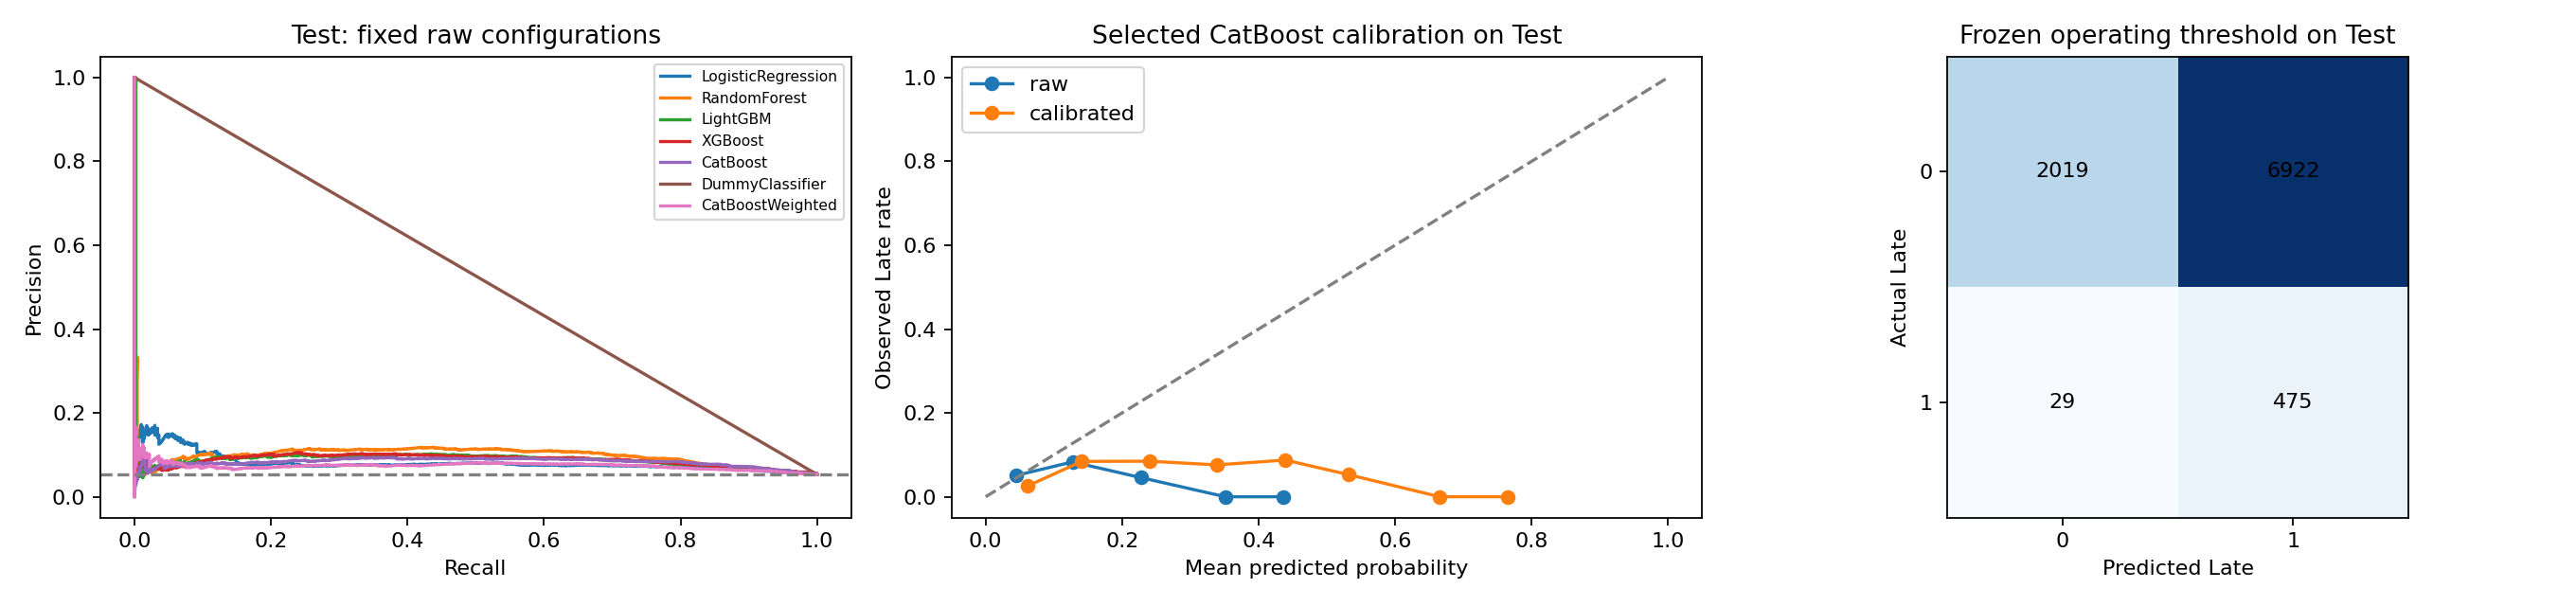

In [7]:
bin_rows = []
for kind, probabilities in [("raw", raw_selected), ("calibrated", calibrated_probability)]:
    codes = np.minimum((probabilities * 10).astype(int), 9)
    for index in range(10):
        mask = codes == index
        bin_rows.append(dict(
            probability_type=kind, bin=index, left=index / 10, right=(index + 1) / 10,
            n=int(mask.sum()), late=int(y_test[mask].sum()),
            mean_probability=float(probabilities[mask].mean()) if mask.any() else np.nan,
            observed_rate=float(y_test[mask].mean()) if mask.any() else np.nan,
        ))
calibration_bins = pd.DataFrame(bin_rows)
calibration_bins.to_csv(tables / "test_calibration_bins.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, probabilities in raw_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    axes[0].plot(recall, precision, label=name)
axes[0].axhline(float(y_test.mean()), linestyle="--", color="gray")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Test: fixed raw configurations")
axes[0].legend(fontsize=7)
for kind, group in calibration_bins.groupby("probability_type", sort=False):
    valid = group.loc[group.n.gt(0)]
    axes[1].plot(valid.mean_probability, valid.observed_rate, marker="o", label=kind)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set(xlabel="Mean predicted probability", ylabel="Observed Late rate", title="Selected CatBoost calibration on Test")
axes[1].legend()
matrix = np.array([[tn, fp], [fn, tp]])
axes[2].imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        axes[2].text(column, row, str(matrix[row, column]), ha="center", va="center")
axes[2].set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted Late", ylabel="Actual Late", title="Frozen operating threshold on Test")
fig.tight_layout()
plot_path = figures / "final_test_results.png"
fig.savefig(plot_path, dpi=160)
display(Image(filename=str(plot_path)))
plt.close(fig)


## Audit and mark final evaluation complete

Check artifact immutability, source hashes and output consistency. The original frozen decision files remain unchanged.

In [8]:
assert len(all_predictions) == 7 * len(test)
assert not all_predictions.duplicated(["model", "order_id"]).any()
assert all_predictions.groupby("model").size().eq(len(test)).all()
assert tn + fp + fn + tp == len(test) and fn + tp == int(y_test.sum())
for record in registry:
    assert sha256_file(ROOT / record["pipeline"]) == record["pipeline_sha256"]
assert sha256_file(ROOT / final_config["calibrator"]) == final_config["calibrator_sha256"]
assert sha256_file(FINAL_CONFIG_PATH) == final_config_hash
for name, digest in final_config["input_hashes"].items():
    assert sha256_file(ROOT / name) == digest
reloaded = pd.read_csv(tables / "selected_test_predictions.csv", float_precision="round_trip")
np.testing.assert_array_equal(reloaded.prediction.to_numpy(dtype=int), prediction)
np.testing.assert_array_equal((reloaded.calibrated_probability.to_numpy() >= threshold).astype(int), prediction)
completed = {
    **plan, "status": "completed", "run_id": run,
    "test_orders": len(test), "test_late": int(y_test.sum()),
    "selected_test_metrics": threshold_metrics,
    "test_probability_comparison": "seven_model_test_comparison.csv",
    "outputs": {path.name: sha256_file(path) for path in tables.glob("*.csv")},
    "package_versions": {**{name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "catboost", "lightgbm", "xgboost"]}, "python": platform.python_version()},
}
(tables / "evaluation_manifest.json").write_text(json.dumps(completed, indent=2), encoding="utf-8")
print("Final Test results:", tables.relative_to(ROOT))
print("Selection unchanged: CatBoost baseline. No classifier/calibrator fitting or threshold adjustment performed.")


Final Test results: outputs\tables\ml_test\20261111_160038_411032
Selection unchanged: CatBoost baseline. No classifier/calibrator fitting or threshold adjustment performed.
